# Notebook 1 — Mecanismo de atención aplicado a una serie de tiempo

**Actividad:** Transformers · Universidad de Cundinamarca
**Autor:** Daniel Contreras

**Problema.** Predecir la temperatura mínima del día siguiente en Melbourne a partir de los 30 días anteriores.

**Idea.** Un LSTM comprime toda la ventana en un único vector, y ese vector tiene que "recordar" todo. Con un mecanismo de **atención aditiva (Bahdanau et al., 2015)** el modelo calcula un peso por cada día de la ventana y construye un *vector de contexto* como suma ponderada de los estados ocultos. Los pesos se pueden visualizar, así que sabemos **a qué días presta atención** el modelo al predecir.

Ecuaciones:  
$e_t = v^\top \tanh(W h_t + b)$  ·  $\alpha_t = \mathrm{softmax}(e_t)$  ·  $c = \sum_t \alpha_t h_t$

Contenido: 1) datos, 2) preparación, 3) modelos, 4) entrenamiento, 5) evaluación, 6) análisis de la atención.

## 1. Carga y exploración de datos

In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
import math, time, random
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"], index_col="Date")
df["Temp"] = pd.to_numeric(df["Temp"], errors="coerce").interpolate()
print(df.shape, df.index.min().date(), "->", df.index.max().date())
df.head()

Dispositivo: cpu
(3650, 1) 1981-01-01 -> 1990-12-31


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


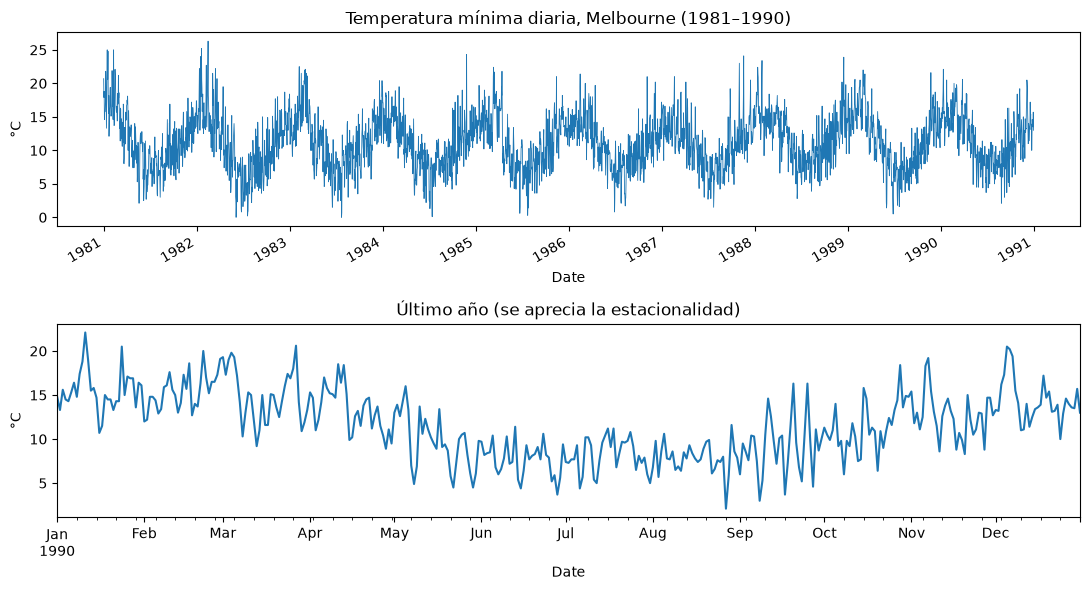

count    3650.00
mean       11.18
std         4.07
min         0.00
25%         8.30
50%        11.00
75%        14.00
max        26.30
Name: Temp, dtype: float64


In [2]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
df["Temp"].plot(ax=ax[0], lw=0.6, title="Temperatura mínima diaria, Melbourne (1981–1990)")
df.loc["1990-01-01":, "Temp"].plot(ax=ax[1], title="Último año (se aprecia la estacionalidad)")
ax[0].set_ylabel("°C"); ax[1].set_ylabel("°C"); plt.tight_layout(); plt.show()
print(df["Temp"].describe().round(2))

## 2. Preparación de los datos
* Partición **cronológica** 70/15/15 (no se mezcla el tiempo: sería fuga de información).
* Normalización *z-score* con media y desviación **solo del conjunto de entrenamiento**.
* Ventanas deslizantes de 30 días → predicción del día 31.

In [3]:
# --- Partición cronológica 70 / 15 / 15 (sin mezclar, para evitar fuga de información) ---
serie = df["Temp"].values.astype("float32")
n = len(serie)
i_tr, i_va = int(n * 0.70), int(n * 0.85)

# El escalador se ajusta SOLO con entrenamiento
mu, sd = serie[:i_tr].mean(), serie[:i_tr].std()
z = (serie - mu) / sd

VENTANA = 30   # días de contexto
def ventanas(z, ini, fin, L=VENTANA):
    X, y = [], []
    for t in range(ini + L, fin):
        X.append(z[t - L:t]); y.append(z[t])
    return (torch.tensor(np.array(X)).unsqueeze(-1),   # (N, L, 1)
            torch.tensor(np.array(y)).unsqueeze(-1))   # (N, 1)

Xtr, ytr = ventanas(z, 0, i_tr)
Xva, yva = ventanas(z, i_tr - VENTANA, i_va)
Xte, yte = ventanas(z, i_va - VENTANA, n)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)

from torch.utils.data import DataLoader, TensorDataset
dl_tr = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
dl_va = DataLoader(TensorDataset(Xva, yva), batch_size=256)

train torch.Size([2525, 30, 1]) | val torch.Size([547, 30, 1]) | test torch.Size([548, 30, 1])


## 3. Modelos
Se comparan un **LSTM simple** (usa solo el último estado oculto) y un **LSTM + atención** (usa todos los estados ponderados).

In [4]:
class AtencionAditiva(nn.Module):
    """Atención de Bahdanau: puntúa cada paso de tiempo y devuelve contexto + pesos."""
    def __init__(self, d):
        super().__init__()
        self.W = nn.Linear(d, d)
        self.v = nn.Linear(d, 1, bias=False)
    def forward(self, H):                      # H: (B, L, d)
        e = self.v(torch.tanh(self.W(H)))      # (B, L, 1)
        alfa = torch.softmax(e, dim=1)         # pesos que suman 1 sobre el tiempo
        contexto = (alfa * H).sum(dim=1)       # (B, d)
        return contexto, alfa.squeeze(-1)

class LSTMAtencion(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.lstm = nn.LSTM(1, d, batch_first=True)
        self.att = AtencionAditiva(d)
        self.out = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x, return_att=False):
        H, _ = self.lstm(x)
        ctx, alfa = self.att(H)
        y = self.out(ctx)
        return (y, alfa) if return_att else y

class LSTMSimple(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.lstm = nn.LSTM(1, d, batch_first=True)
        self.out = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        H, _ = self.lstm(x)
        return self.out(H[:, -1])

m_lstm, m_att = LSTMSimple(), LSTMAtencion()
print("Parámetros LSTM:", sum(p.numel() for p in m_lstm.parameters()))
print("Parámetros LSTM+Atención:", sum(p.numel() for p in m_att.parameters()))

Parámetros LSTM: 19265
Parámetros LSTM+Atención: 23489


## 4. Entrenamiento

In [5]:
def entrenar(model, epocas=40, lr=1e-3, paciencia=8, nombre="modelo"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    hist = {"train": [], "val": []}
    mejor, mejor_estado, sin_mejora = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        model.train(); tr = 0
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            pred = model(xb)
            if isinstance(pred, tuple): pred = pred[0]
            loss = loss_fn(pred, yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tr += loss.item() * len(xb)
        tr /= len(dl_tr.dataset)
        model.eval(); va = 0
        with torch.no_grad():
            for xb, yb in dl_va:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb)
                if isinstance(pred, tuple): pred = pred[0]
                va += loss_fn(pred, yb).item() * len(xb)
        va /= len(dl_va.dataset)
        hist["train"].append(tr); hist["val"].append(va)
        if va < mejor:
            mejor, sin_mejora = va, 0
            mejor_estado = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            sin_mejora += 1
        if ep % 5 == 0 or ep == 1:
            print(f"[{nombre}] época {ep:02d} | pérdida train {tr:.4f} | val {va:.4f}")
        if sin_mejora >= paciencia:
            print(f"[{nombre}] parada temprana en la época {ep}"); break
    model.load_state_dict(mejor_estado)
    print(f"[{nombre}] listo en {time.time()-t0:.1f}s | mejor val {mejor:.4f}")
    return hist

@torch.no_grad()
def evaluar(model, X, y):
    model.eval()
    pred = model(X.to(device))
    if isinstance(pred, tuple): pred = pred[0]
    p = pred.cpu().numpy().ravel() * sd + mu      # de vuelta a °C
    r = y.numpy().ravel() * sd + mu
    return {"MAE": mean_absolute_error(r, p),
            "RMSE": math.sqrt(mean_squared_error(r, p))}, p, r

# Línea base: persistencia (predecir que mañana = hoy)
r_real = yte.numpy().ravel() * sd + mu
p_pers = Xte[:, -1, 0].numpy() * sd + mu
base = {"MAE": mean_absolute_error(r_real, p_pers),
        "RMSE": math.sqrt(mean_squared_error(r_real, p_pers))}
print("Persistencia ->", {k: round(v, 3) for k, v in base.items()})

Persistencia -> {'MAE': 2.036, 'RMSE': 2.572}


In [6]:
torch.manual_seed(SEED); m_lstm = LSTMSimple()
h_lstm = entrenar(m_lstm, nombre="LSTM")
torch.manual_seed(SEED); m_att = LSTMAtencion()
h_att = entrenar(m_att, nombre="LSTM+Atención")

[LSTM] época 01 | pérdida train 0.7255 | val 0.4509


[LSTM] época 05 | pérdida train 0.4082 | val 0.3609


[LSTM] época 10 | pérdida train 0.3635 | val 0.3242


[LSTM] época 15 | pérdida train 0.3578 | val 0.3205


[LSTM] época 20 | pérdida train 0.3571 | val 0.3207


[LSTM] época 25 | pérdida train 0.3564 | val 0.3161


... (8 outputs left out)

[LSTM+Atención] época 25 | pérdida train 0.3747 | val 0.3315


[LSTM+Atención] época 30 | pérdida train 0.3593 | val 0.3220


[LSTM+Atención] época 35 | pérdida train 0.3618 | val 0.3247


[LSTM+Atención] época 40 | pérdida train 0.3591 | val 0.3263
[LSTM+Atención] listo en 9.8s | mejor val 0.3190


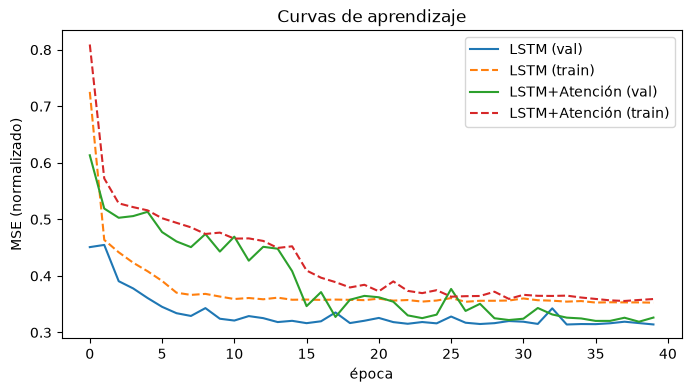

In [7]:
plt.figure(figsize=(8, 4))
for h, n_ in [(h_lstm, "LSTM"), (h_att, "LSTM+Atención")]:
    plt.plot(h["val"], label=f"{n_} (val)"); plt.plot(h["train"], "--", label=f"{n_} (train)")
plt.xlabel("época"); plt.ylabel("MSE (normalizado)"); plt.legend(); plt.title("Curvas de aprendizaje"); plt.show()

## 5. Evaluación en el conjunto de prueba (en °C)

                   MAE   RMSE
Persistencia     2.036  2.572
LSTM             1.716  2.201
LSTM + Atención  1.716  2.198


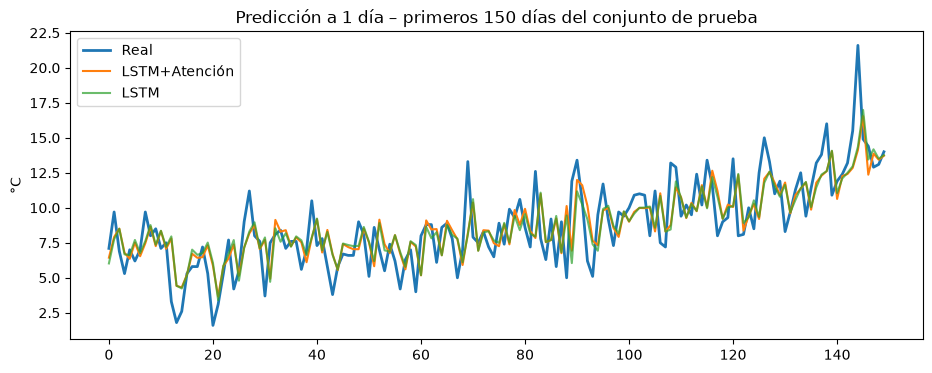

In [8]:
res = {"Persistencia": base}
m1, p1, r = evaluar(m_lstm, Xte, yte); res["LSTM"] = m1
m2, p2, r = evaluar(m_att, Xte, yte);  res["LSTM + Atención"] = m2
tabla = pd.DataFrame(res).T.round(3); print(tabla)

plt.figure(figsize=(11, 4))
k = slice(0, 150)
plt.plot(r[k], label="Real", lw=2); plt.plot(p2[k], label="LSTM+Atención"); plt.plot(p1[k], label="LSTM", alpha=.7)
plt.title("Predicción a 1 día – primeros 150 días del conjunto de prueba"); plt.ylabel("°C"); plt.legend(); plt.show()

## 6. Análisis de la atención
Extraemos los pesos $\alpha_t$ del modelo. El eje x es la posición en la ventana: `-30` es el día más antiguo y `-1` es **ayer**.

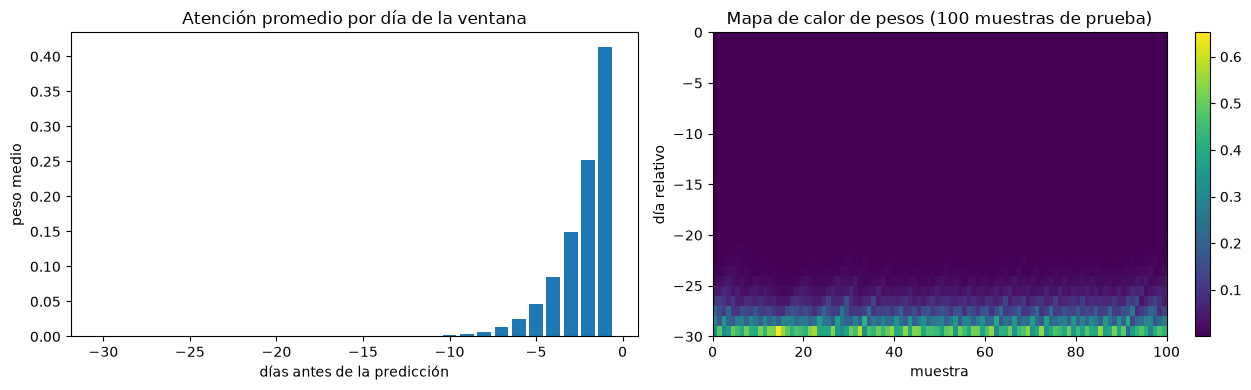

Peso medio de los últimos 3 días : 0.816
Peso medio de los primeros 10 días: 0.0
Día con mayor peso medio: t-1


In [9]:
m_att.eval()
with torch.no_grad():
    _, alfa = m_att(Xte.to(device), return_att=True)
alfa = alfa.cpu().numpy()              # (N, 30)
prom = alfa.mean(0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(-VENTANA, 0), prom)
ax[0].set_title("Atención promedio por día de la ventana"); ax[0].set_xlabel("días antes de la predicción"); ax[0].set_ylabel("peso medio")
im = ax[1].imshow(alfa[:100].T, aspect="auto", cmap="viridis", extent=[0, 100, -VENTANA, 0])
ax[1].set_title("Mapa de calor de pesos (100 muestras de prueba)"); ax[1].set_xlabel("muestra"); ax[1].set_ylabel("día relativo")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

print("Peso medio de los últimos 3 días :", prom[-3:].sum().round(3))
print("Peso medio de los primeros 10 días:", prom[:10].sum().round(3))
print("Día con mayor peso medio: t-%d" % (VENTANA - prom.argmax()))

## 7. Conclusiones del notebook
* La **atención** convierte la ventana en un contexto ponderado y los pesos son interpretables.
* Compare en la tabla de la sección 5 si la atención mejora al LSTM simple y a la línea base de persistencia.
* Los mapas de calor muestran qué días pesan más; analícelos en el informe.

**Referencia:** Bahdanau, D., Cho, K., & Bengio, Y. (2015). *Neural machine translation by jointly learning to align and translate.* ICLR.